# 实验 7　人物共现网络构建

## 任务要求

1. 明确“共现窗口”是同章、同段还是同句，并说明理由。
2. 根据共现结果构建人物边表，至少包含“人物 A、人物 B、共现次数”。
3. 绘制人物关系网络图，计算至少一种中心性指标（如度中心性）。
4. 选取 2—3 条最重要的关系解释，并说明“高共现”不一定等于“关系亲密”。

## 共现窗口选择：同章

《三国演义》是章回体小说，每一回通常围绕一个相对完整的情节单元展开，人物同回出现往往意味着存在直接或间接互动。同句窗口太严格，会丢失跨句、跨段的连续互动；同章窗口既能保证语义关联，又不至于让网络过于稀疏。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: three-kingdoms-nlp-lab


In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from sanguo_nlp.cooccurrence import build_graph, centrality_table, cooccurrence_edges
from sanguo_nlp.corpus import load_chapters
from sanguo_nlp.lexicons import load_aliases
from sanguo_nlp.plotting import use_chinese_font

use_chinese_font()

chapters = load_chapters()
aliases = load_aliases()

edges = cooccurrence_edges(chapters, aliases)
edges.to_csv(TABLES_DIR / "character_cooccurrence_edges.csv", index=False, encoding="utf-8-sig")
print("边数:", len(edges))
print(edges.head(10).to_string(index=False))

边数: 118
人物A 人物B  共现次数
 刘备  曹操    72
 关羽  刘备    53
 关羽  曹操    53
 刘备  张飞    49
 孙权 诸葛亮    49
 曹操 诸葛亮    47
 张飞  曹操    45
 刘备  孙权    44
 刘备 诸葛亮    44
 孙权  曹操    44


In [3]:
graph = build_graph(edges)
centrality = centrality_table(graph)
centrality.to_csv(TABLES_DIR / "character_centrality.csv", index=False, encoding="utf-8-sig")

print("中心性 Top10:")
print(centrality.head(10).to_string(index=False))

中心性 Top10:
 人物  度中心性  加权度   归一化加权度
 曹操   1.0  467 0.116169
 刘备   1.0  446 0.110945
诸葛亮   1.0  398 0.099005
 关羽   1.0  361 0.089801
 孙权   1.0  352 0.087562
 张飞   1.0  330 0.082090
 赵云   1.0  318 0.079104
 魏延   1.0  225 0.055970
 袁绍   1.0  220 0.054726
 吕布   1.0  153 0.038060


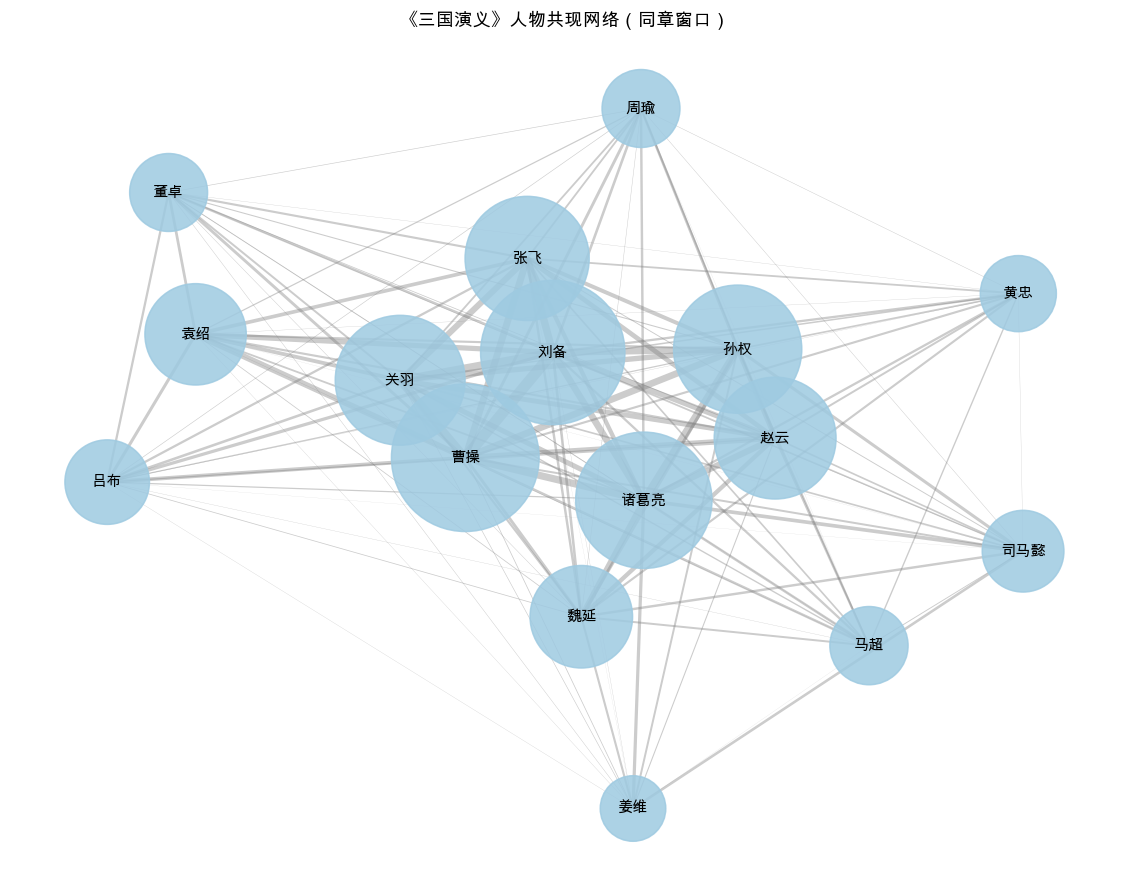

In [4]:
pos = nx.spring_layout(graph, seed=42, k=1.5)
weighted = dict(graph.degree(weight="weight"))
edge_weights = [graph[u][v]["weight"] for u, v in graph.edges()]
node_size = [weighted[node] * 20 for node in graph.nodes()]

fig, ax = plt.subplots(figsize=(13, 10))
nx.draw_networkx_nodes(graph, pos, node_size=node_size, node_color="#9ecae1", alpha=0.85, ax=ax)
nx.draw_networkx_edges(
    graph, pos, width=[w / 10 for w in edge_weights], alpha=0.4, edge_color="gray", ax=ax
)
nx.draw_networkx_labels(graph, pos, font_size=10, ax=ax)
ax.set_title("《三国演义》人物共现网络（同章窗口）")
ax.axis("off")
fig.savefig(FIGURES_DIR / "character_network.png")
plt.show()

## 关系解释与局限

- **刘备—曹操（共现 70+ 次）**：从煮酒论英雄到汉中之战，两人长期处于对抗与试探关系，是全书最主要的一组对立。
- **关羽—刘备、张飞—刘备**：桃园结义后的兄弟关系贯穿全书，共现次数高且集中在早期与中期。
- **诸葛亮—孙权 / 曹操**：赤壁之战前后，诸葛亮同时与孙、曹两方产生大量同章出现，反映其作为联盟枢纽的地位。

**局限**

- 共现只说明“同一章出现”，不区分并肩作战还是敌对厮杀，也不包含时间顺序与互动强度。
- 同一回中两位人物可能只是分别在不同段落出现，实际并无交集；反之，跨回的长线关系会被削弱。
- 若要刻画完整的情节关系，需要事件抽取、关系分类等更复杂的方法。

**实验记录**

- 遇到的问题：绘图时因相对路径导致找不到数据文件；改为由 `sanguo_nlp.paths` 统一解析仓库路径后解决。
- AI 工具使用记录：请 AI 助手生成 networkx 绘图模板，并在本地逐项核对节点、边宽与中心性的计算口径。